<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/kinetic_theory/kintheory_ch1_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Kinetic Theory* — `kintheory_ch1_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Kinetic Theory Chapter 1 — Figures
**Kinetic Theory · Ch 1: Things Bumping Into Other Things**  
Tong lectures — SeoulTech PSE Lab

Figures produced:
- `kt_fig01_mean_free_path.png` — Hard sphere sweeping cylinder; mean free path geometry
- `kt_fig02_random_walk.png` — 1D random walk trajectories + spreading Gaussian P(x,t)
- `kt_fig03_viscosity.png` — Couette flow between two plates; linear velocity profile
- `kt_fig04_thermal_conductivity.png` — Temperature gradient and heat flux between plates

All figures use the dark background palette matching `gr_slides.css`.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyBboxPatch, Ellipse
from matplotlib.patches import Rectangle
import os

os.makedirs('figures', exist_ok=True)

# ── Dark theme palette (matching gr_slides.css) ──
BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
GOLD    = '#d4a017'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

def dark_fig(w=8, h=5):
    fig, ax = plt.subplots(figsize=(w, h))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(BG)
    for spine in ax.spines.values():
        spine.set_color(BORDER)
    ax.tick_params(colors=MUTED)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(GOLD)
    return fig, ax

SAVE_KW = dict(dpi=150, bbox_inches='tight', facecolor=BG)
print('Setup complete. Dark palette loaded.')

Setup complete. Dark palette loaded.


## Fig 1 — Mean Free Path: Hard Sphere Geometry

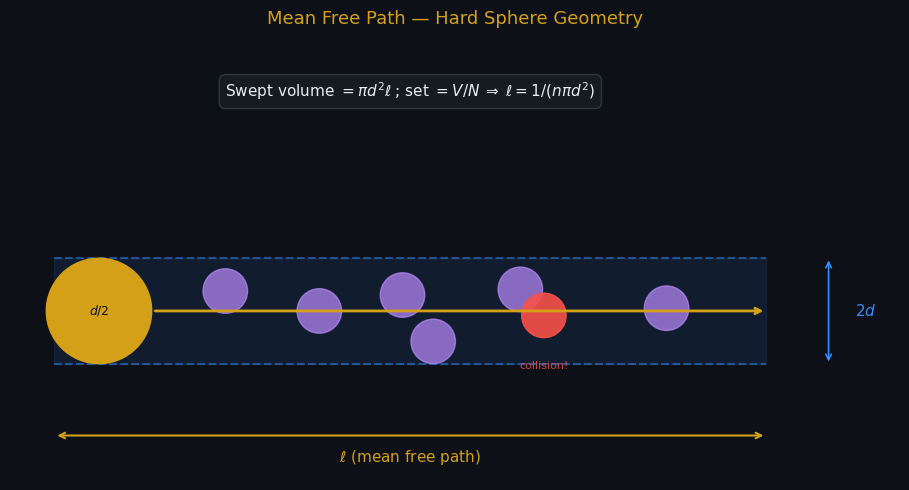

Saved kt_fig01_mean_free_path.png


In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlim(0, 10)
ax.set_ylim(-1.5, 3.5)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# ── Cylinder (mean free path swept volume) ──
# Drawn as a rectangle with rounded ends representing the tube
cyl_x = np.array([0.5, 8.5])
cyl_top = 1.0
cyl_bot = -0.2
# Top and bottom edges
ax.fill_between(cyl_x, cyl_bot, cyl_top,
                color=BLUE, alpha=0.10, zorder=1)
ax.plot(cyl_x, [cyl_top, cyl_top], color=BLUE, lw=1.5, alpha=0.5, ls='--')
ax.plot(cyl_x, [cyl_bot, cyl_bot], color=BLUE, lw=1.5, alpha=0.5, ls='--')

# ── Moving particle (left) ──
cx, cy, r = 1.0, 0.4, 0.6   # center, radius of moving particle
circle_main = Circle((cx, cy), r, color=GOLD, zorder=5, linewidth=0)
ax.add_patch(circle_main)
ax.text(cx, cy, r'$d/2$', ha='center', va='center', fontsize=9,
        color=BG, fontweight='bold', zorder=6)

# Arrow showing direction of travel
ax.annotate('', xy=(8.5, cy), xytext=(cx + r, cy),
            arrowprops=dict(arrowstyle='->', color=GOLD, lw=2.0), zorder=6)

# ── Scattered particles (inside cylinder) ──
np.random.seed(7)
for _ in range(6):
    x_p = np.random.uniform(2.0, 7.5)
    y_p = np.random.uniform(cyl_bot + 0.2, cyl_top - 0.2)
    r_p = 0.25
    c = Circle((x_p, y_p), r_p, color=PURPLE, alpha=0.7, zorder=3)
    ax.add_patch(c)

# One collision particle in path
cx2, cy2 = 6.0, 0.35
r2 = 0.25
c2 = Circle((cx2, cy2), r2, color=RED, alpha=0.9, zorder=4)
ax.add_patch(c2)
ax.text(cx2, cy2 - 0.6, 'collision!', ha='center', fontsize=8,
        color=RED, alpha=0.8)

# ── Dimension labels ──
# Diameter label
ax.annotate('', xy=(cx, cy + r), xytext=(cx, cy - r),
            arrowprops=dict(arrowstyle='<->', color=MUTED, lw=1.2))
ax.text(cx - 0.5, cy, '$d$', ha='center', va='center',
        fontsize=12, color=TEXT)

# Length label
ax.annotate('', xy=(8.5, -1.0), xytext=(0.5, -1.0),
            arrowprops=dict(arrowstyle='<->', color=GOLD, lw=1.5))
ax.text(4.5, -1.3, r'$\ell$ (mean free path)', ha='center',
        fontsize=11, color=GOLD)

# Width label (2d)
ax.annotate('', xy=(9.2, cyl_top), xytext=(9.2, cyl_bot),
            arrowprops=dict(arrowstyle='<->', color=BLUE, lw=1.2))
ax.text(9.5, 0.4, '$2d$', ha='left', va='center', fontsize=11, color=BLUE)

# Formula
ax.text(4.5, 2.8,
        r'Swept volume $= \pi d^2\ell\;$; set $= V/N$'
        r'$\;\Rightarrow\; \ell = 1/(n\pi d^2)$',
        ha='center', fontsize=11, color=TEXT,
        bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE,
                  edgecolor=BORDER, linewidth=1))

ax.set_title('Mean Free Path — Hard Sphere Geometry', color=GOLD, fontsize=13, pad=8)
plt.tight_layout()
plt.savefig('figures/kt_fig01_mean_free_path.png', **SAVE_KW)
plt.show()
print('Saved kt_fig01_mean_free_path.png')

## Fig 2 — Random Walk + Spreading Gaussian

<>:29: SyntaxWarning: invalid escape sequence '\e'
<>:29: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_9356/3259391876.py:29: SyntaxWarning: invalid escape sequence '\e'
  ax1.set_ylabel('Position $x/\ell$', color=TEXT, fontsize=11)


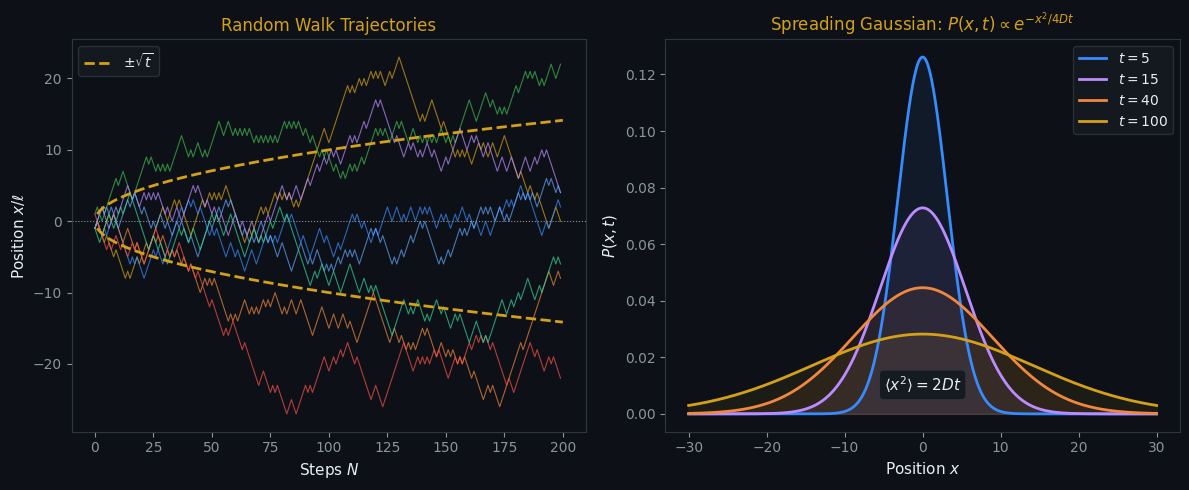

Saved kt_fig02_random_walk.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

# ── Left panel: sample random walk trajectories ──
ax1 = axes[0]
ax1.set_facecolor(BG)
for sp in ax1.spines.values():
    sp.set_color(BORDER)
ax1.tick_params(colors=MUTED)

np.random.seed(42)
N_steps = 200
N_walkers = 8
colors_walk = [GOLD, BLUE, GREEN, PURPLE, ORANGE, RED, '#60a5fa', '#34d399']

for i in range(N_walkers):
    steps = np.random.choice([-1, 1], size=N_steps)
    x = np.cumsum(steps)
    t = np.arange(N_steps)
    ax1.plot(t, x, color=colors_walk[i], lw=0.8, alpha=0.7)

# sqrt(t) envelope
t_arr = np.linspace(1, N_steps, 300)
ax1.plot(t_arr,  np.sqrt(t_arr), color=GOLD, lw=2.0, ls='--', label=r'$\pm\sqrt{t}$')
ax1.plot(t_arr, -np.sqrt(t_arr), color=GOLD, lw=2.0, ls='--')
ax1.axhline(0, color=MUTED, lw=0.8, ls=':')

ax1.set_xlabel('Steps $N$', color=TEXT, fontsize=11)
ax1.set_ylabel('Position $x/\ell$', color=TEXT, fontsize=11)
ax1.set_title('Random Walk Trajectories', color=GOLD, fontsize=12)
ax1.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER,
           labelcolor=TEXT)
ax1.xaxis.label.set_color(TEXT)
ax1.yaxis.label.set_color(TEXT)

# ── Right panel: Gaussian P(x,t) at several times ──
ax2 = axes[1]
ax2.set_facecolor(BG)
for sp in ax2.spines.values():
    sp.set_color(BORDER)
ax2.tick_params(colors=MUTED)

x = np.linspace(-30, 30, 500)
times = [5, 15, 40, 100]
colors_t = [BLUE, PURPLE, ORANGE, GOLD]

for t_val, col in zip(times, colors_t):
    D = 1.0  # dimensionless D
    sigma2 = 2 * D * t_val
    P = (1 / np.sqrt(2 * np.pi * sigma2)) * np.exp(-x**2 / (2 * sigma2))
    ax2.plot(x, P, color=col, lw=2.0, label=f'$t = {t_val}$')
    ax2.fill_between(x, P, alpha=0.08, color=col)

ax2.set_xlabel('Position $x$', color=TEXT, fontsize=11)
ax2.set_ylabel('$P(x,t)$', color=TEXT, fontsize=11)
ax2.set_title(r'Spreading Gaussian: $P(x,t) \propto e^{-x^2/4Dt}$',
              color=GOLD, fontsize=12)
ax2.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER,
           labelcolor=TEXT)
ax2.xaxis.label.set_color(TEXT)
ax2.yaxis.label.set_color(TEXT)

# annotation
ax2.text(0, 0.008, r'$\langle x^2\rangle = 2Dt$',
         ha='center', fontsize=11, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=SURFACE,
                   edgecolor=BORDER))

plt.tight_layout()
plt.savefig('figures/kt_fig02_random_walk.png', **SAVE_KW)
plt.show()
print('Saved kt_fig02_random_walk.png')

## Fig 3 — Viscosity: Couette Flow Between Plates

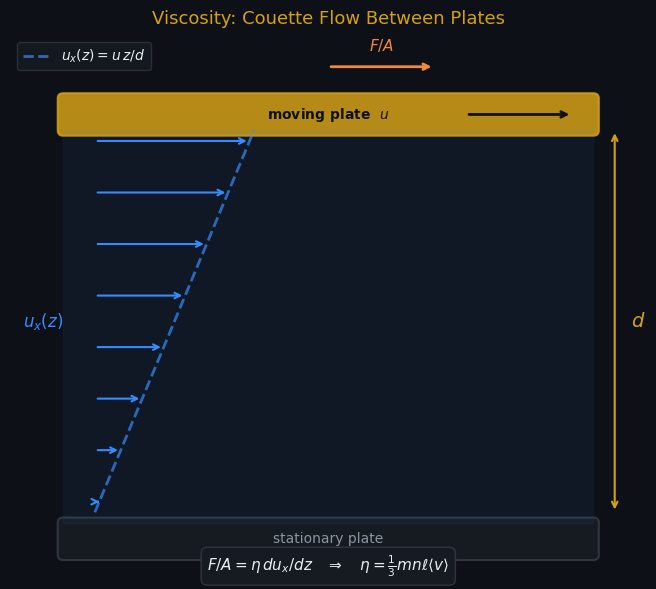

Saved kt_fig03_viscosity.png


In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-0.6, 4.5)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])

# ── Plates ──
plate_width = 5.0
# Lower plate (stationary)
lower = FancyBboxPatch((0, -0.4), plate_width, 0.3,
                        boxstyle='round,pad=0.05',
                        facecolor=SURFACE, edgecolor=BORDER, lw=1.5)
ax.add_patch(lower)
ax.text(plate_width/2, -0.25, 'stationary plate', ha='center', va='center',
        fontsize=10, color=MUTED)

# Upper plate (moving)
upper = FancyBboxPatch((0, 3.6), plate_width, 0.3,
                        boxstyle='round,pad=0.05',
                        facecolor=GOLD, edgecolor=GOLD, lw=1.5, alpha=0.85)
ax.add_patch(upper)
ax.text(plate_width/2, 3.75, 'moving plate  $u$', ha='center', va='center',
        fontsize=10, color=BG, fontweight='bold')
# velocity arrow on upper plate
ax.annotate('', xy=(4.8, 3.75), xytext=(3.8, 3.75),
            arrowprops=dict(arrowstyle='->', color=BG, lw=2.0))

# ── Fluid (hatched region) ──
ax.fill_between([0, plate_width], [-0.1, -0.1], [3.6, 3.6],
                color=BLUE, alpha=0.06)

# ── Velocity profile arrows ──
d_plate = 3.6  # plate separation in plot units
u_max = 1.5    # max arrow length
n_arrows = 8
z_vals = np.linspace(0.1, 3.5, n_arrows)
u_vals = u_max * z_vals / d_plate

for z, u in zip(z_vals, u_vals):
    ax.annotate('', xy=(0.3 + u, z), xytext=(0.3, z),
                arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5))

# Profile line
z_line = np.linspace(0, d_plate, 100)
u_line = 0.3 + u_max * z_line / d_plate
ax.plot(u_line, z_line, color=BLUE, lw=2.0, ls='--', alpha=0.7,
        label=r'$u_x(z) = u\,z/d$')

# ── Labels ──
# Diameter label
ax.annotate('', xy=(5.2, 3.6), xytext=(5.2, 0.0),
            arrowprops=dict(arrowstyle='<->', color=GOLD, lw=1.5))
ax.text(5.35, 1.8, '$d$', ha='left', va='center', fontsize=14, color=GOLD)

# u_x label
ax.text(0.0, 1.8, r'$u_x(z)$', ha='right', va='center', fontsize=12, color=BLUE)

# Force label
ax.annotate('', xy=(3.5, 4.2), xytext=(2.5, 4.2),
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.0))
ax.text(3.0, 4.35, '$F/A$', ha='center', fontsize=11, color=ORANGE)

# Formula box  ← \tfrac → \frac 로 수정
ax.text(2.5, -0.55,
        r'$F/A = \eta\,du_x/dz \quad\Rightarrow\quad \eta = \frac{1}{3}mn\ell\langle v\rangle$',
        ha='center', fontsize=11, color=TEXT,
        bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE,
                  edgecolor=BORDER, lw=1))

ax.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER,
          labelcolor=TEXT, loc='upper left')
ax.set_title('Viscosity: Couette Flow Between Plates', color=GOLD, fontsize=13, pad=8)

plt.tight_layout()
plt.savefig('figures/kt_fig03_viscosity.png', **SAVE_KW)
plt.show()
print('Saved kt_fig03_viscosity.png')

## Fig 4 — Thermal Conductivity: Temperature Gradient

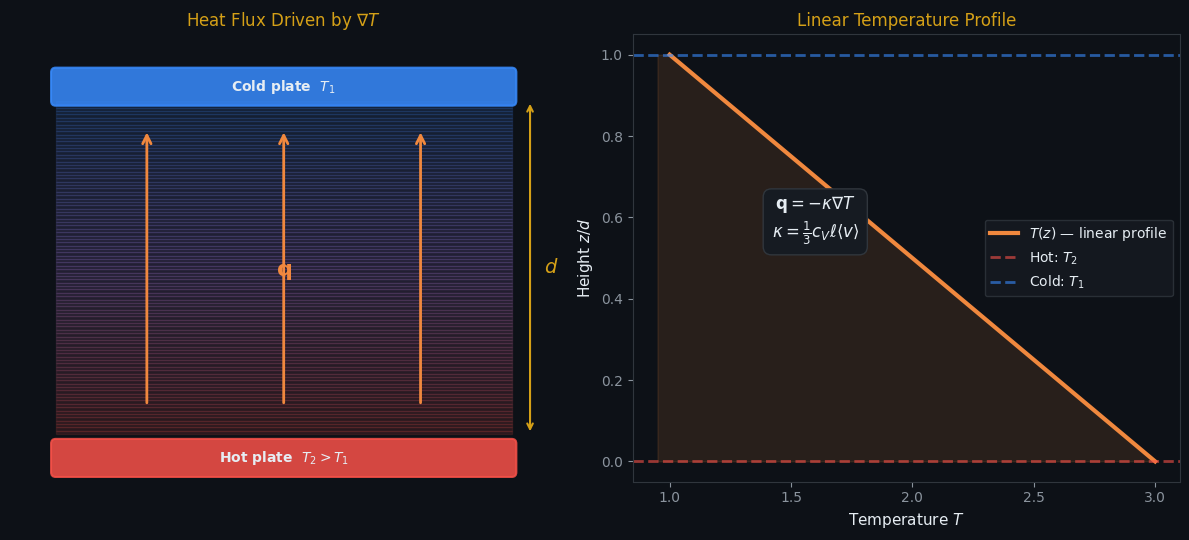

Saved kt_fig04_thermal_conductivity.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.patch.set_facecolor(BG)

ax1 = axes[0]
ax1.set_facecolor(BG)
for sp in ax1.spines.values():
    sp.set_visible(False)
ax1.set_xlim(-0.5, 5.5)
ax1.set_ylim(-0.5, 4.2)
ax1.set_xticks([])
ax1.set_yticks([])

plate_w = 5.0

hot = FancyBboxPatch((0, -0.4), plate_w, 0.3,
                      boxstyle='round,pad=0.05',
                      facecolor=RED, edgecolor=RED, lw=1.5, alpha=0.85)
ax1.add_patch(hot)
ax1.text(plate_w/2, -0.25, r'Hot plate  $T_2 > T_1$', ha='center',
         va='center', fontsize=10, color=TEXT, fontweight='bold')

cold = FancyBboxPatch((0, 3.5), plate_w, 0.3,
                       boxstyle='round,pad=0.05',
                       facecolor=BLUE, edgecolor=BLUE, lw=1.5, alpha=0.85)
ax1.add_patch(cold)
ax1.text(plate_w/2, 3.65, r'Cold plate  $T_1$', ha='center',
         va='center', fontsize=10, color=TEXT, fontweight='bold')

z_grad = np.linspace(0, 3.5, 100)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('hot_cold', [RED, PURPLE, BLUE])
for i, z in enumerate(z_grad[:-1]):
    frac = i / len(z_grad)
    col = cmap(frac)
    ax1.fill_between([0, plate_w], z, z_grad[i+1], color=col, alpha=0.12)

for x_pos in [1.0, 2.5, 4.0]:
    ax1.annotate('', xy=(x_pos, 3.2), xytext=(x_pos, 0.3),
                arrowprops=dict(arrowstyle='->', color=ORANGE,
                                lw=2.0, mutation_scale=15))

ax1.text(2.5, 1.7, r'$\mathbf{q}$', ha='center', va='center',
         fontsize=16, color=ORANGE, fontweight='bold')

ax1.annotate('', xy=(5.2, 3.5), xytext=(5.2, 0.0),
            arrowprops=dict(arrowstyle='<->', color=GOLD, lw=1.5))
ax1.text(5.35, 1.75, '$d$', ha='left', va='center', fontsize=14, color=GOLD)

ax1.set_title('Heat Flux Driven by $\\nabla T$', color=GOLD, fontsize=12)

ax2 = axes[1]
ax2.set_facecolor(BG)
for sp in ax2.spines.values():
    sp.set_color(BORDER)
ax2.tick_params(colors=MUTED)

z = np.linspace(0, 1, 200)
T_cold, T_hot = 1.0, 3.0
T_linear = T_hot - (T_hot - T_cold) * z

ax2.plot(T_linear, z, color=ORANGE, lw=3.0, label='$T(z)$ — linear profile')
ax2.fill_betweenx(z, T_cold - 0.05, T_linear, alpha=0.12, color=ORANGE)

ax2.axhline(0, color=RED, lw=2.0, ls='--', alpha=0.6, label=r'Hot: $T_2$')
ax2.axhline(1, color=BLUE, lw=2.0, ls='--', alpha=0.6, label=r'Cold: $T_1$')

ax2.set_xlabel('Temperature $T$', color=TEXT, fontsize=11)
ax2.set_ylabel('Height $z/d$', color=TEXT, fontsize=11)
ax2.set_title('Linear Temperature Profile', color=GOLD, fontsize=12)
ax2.xaxis.label.set_color(TEXT)
ax2.yaxis.label.set_color(TEXT)

ax2.text(1.6, 0.55,
         r'$\mathbf{q} = -\kappa\nabla T$'
         '\n'
         r'$\kappa = \frac{1}{3}c_V\ell\langle v\rangle$',
         ha='center', fontsize=12, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.5', facecolor=SURFACE,
                   edgecolor=BORDER, lw=1))

ax2.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)

plt.tight_layout()
plt.savefig('figures/kt_fig04_thermal_conductivity.png', **SAVE_KW)
plt.show()
print('Saved kt_fig04_thermal_conductivity.png')

## Download all figures as zip

In [6]:
import zipfile, os

zip_path = 'kt_ch1_figures.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)
            print(f'  Added: {fname}')

print(f'\nZip created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path) / 1024:.1f} KB')

try:
    from google.colab import files
    files.download(zip_path)
    print('Download started!')
except ImportError:
    print(f'Not running in Colab — file saved locally as: {zip_path}')

  Added: kt_fig01_mean_free_path.png
  Added: kt_fig02_random_walk.png
  Added: kt_fig03_viscosity.png
  Added: kt_fig04_thermal_conductivity.png

Zip created: kt_ch1_figures.zip
Size: 412.0 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
